# LJSpeech Dataset Preparation and Preprocessing

## Objective
Prepare and validate the LJSpeech dataset for reproducible
single-speaker text-to-speech experiments.

## Protocol
- Random seed: 42
- Train/validation/test ratio: 80/10/10
- Audio: validate existing WAV files without unnecessary modification
- Text: use normalized text for LJSpeech transcriptions

In [ ]:
from pathlib import Path
import os
import sys
import platform
import shutil
import random
import numpy as np
import pandas as pd

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("Python version:", sys.version)
print("Platform:", platform.platform())
print("Current directory:", Path.cwd())#number1

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
Current directory: /content


In [ ]:

import subprocess

data_dir = Path("/content")
archive = data_dir / "LJSpeech-1.1.tar.bz2"
dataset_dir = data_dir / "LJSpeech-1.1"

# Download only if the archive is not already present
if not archive.exists():
    subprocess.run([
        "wget", "-c",
        "-O", str(archive),
        "https://data.keithito.com/data/speech/LJSpeech-1.1.tar.bz2"
    ], check=True)

if not (dataset_dir / "metadata.csv").exists():
    subprocess.run([
        "tar", "-xjf", str(archive), "-C", str(data_dir)
    ], check=True)

print("Metadata exists:", (dataset_dir / "metadata.csv").exists())
print("WAV folder exists:", (dataset_dir / "wavs").is_dir())#number2

Metadata exists: True
WAV folder exists: True


In [5]:
METADATA_PATH = Path("/content/LJSpeech-1.1/metadata.csv")

initial_df = pd.read_csv(
    METADATA_PATH,
    sep="|",
    header=None,
    names=["id", "text", "normalized_text"],
    dtype=str,
    keep_default_na=False
)

print("Total records:", len(initial_df))
print(
    "Initially empty normalized_text:",
    (initial_df["normalized_text"].str.strip() == "").sum()
)

Total records: 13100
Initially empty normalized_text: 16


In [6]:

empty_normalized = initial_df[
    initial_df["normalized_text"].str.strip() == ""
].copy()

empty_normalized["text_length"] = empty_normalized["text"].str.len()
empty_normalized["contains_pipe"] = empty_normalized["text"].str.contains(
    r"\|", regex=True
)

display(
    empty_normalized[
        ["id", "text", "text_length", "contains_pipe"]
    ].to_string(index=False)
)#number4

"        id                                                                                                                                                                                                                                                                                                                                        text  text_length  contains_pipe\nLJ004-0076                                                                     Disease, cold, famine, nakedness, and contagious and polluted air are not lawful punishments in the hands of the civil magistrates;|Disease, cold, famine, nakedness, and contagious and polluted air are not lawful punishments in the hands of the civil magistrates;          263           True\nLJ004-0079                                                                                                                                                                         All measures and practices in prison which may injure him in any way are ill

During the initial metadata loading, 16 normalized_text fields were unexpectedly parsed as empty. After investigation, I found that all 13,100 lines contained exactly two pipe delimiters (|).
Solution: By using line.split("|", 2) to separate the three metadata fields and handled surrounding quotation marks.
Validation: Record count, duplicate IDs, empty text fields, and corresponding audio files were all checked.

### 1. Dataset Loading and Metadata Validation

The LJSpeech-1.1 dataset was used for the text-to-speech experiments. It contains audio recordings paired with textual transcriptions. During the initial inspection, 13,100 metadata records and 13,100 WAV files were identified.

In [7]:
from pathlib import Path
from collections import Counter

METADATA_PATH = Path("/content/LJSpeech-1.1/metadata.csv")

field_counts = Counter()
malformed_lines = []

with open(METADATA_PATH, "r", encoding="utf-8") as f:
    for line_number, line in enumerate(f, start=1):
        # LJSpeech metadata is expected to contain 3 pipe-separated fields.
        count = line.count("|")
        field_counts[count] += 1

        if count != 2:
            malformed_lines.append({
                "line_number": line_number,
                "pipe_count": count,
                "raw_line": line.rstrip("\n")
            })

print("Total raw lines:", sum(field_counts.values()))
print("Pipe count distribution:", field_counts)
print("Lines not containing exactly 2 pipe characters:",
      len(malformed_lines))

for item in malformed_lines[:20]:
    print(f"\nLine {item['line_number']}:")
    print(repr(item["raw_line"]))#number8

Total raw lines: 13100
Pipe count distribution: Counter({2: 13100})
Lines not containing exactly 2 pipe characters: 0


In [8]:
from pathlib import Path
import pandas as pd

DATASET_DIR = Path("/content/LJSpeech-1.1")
METADATA_PATH = DATASET_DIR / "metadata.csv"
WAV_DIR = DATASET_DIR / "wavs"

records = []
parse_errors = []

with open(METADATA_PATH, "r", encoding="utf-8") as f:
    for line_number, line in enumerate(f, start=1):
        line = line.rstrip("\r\n")

        # Split into ID, text and normalized text at the first two pipes.
        parts = line.split("|", 2)

        if len(parts) != 3:
            parse_errors.append((line_number, line))
            continue

        sample_id = parts[0].strip()
        text = parts[1].strip()
        normalized_text = parts[2].strip()

        # Remove surrounding quote characters from malformed records.
        text = text.strip('"')
        normalized_text = normalized_text.strip('"')

        records.append({
            "id": sample_id,
            "text": text,
            "normalized_text": normalized_text
        })

df = pd.DataFrame(records)

print("Parsed rows:", len(df))
print("Parse errors:", len(parse_errors))
print("Duplicate IDs:", df["id"].duplicated().sum())
print("Empty IDs:", (df["id"].str.strip() == "").sum())
print("Empty text:", (df["text"].str.strip() == "").sum())
print(
    "Empty normalized text:",
    (df["normalized_text"].str.strip() == "").sum()
)

print("\nPreviously problematic records:")
display(
    df[df["id"].isin([
        "LJ004-0076", "LJ004-0079", "LJ004-0250",
        "LJ005-0028", "LJ005-0030", "LJ005-0077",
        "LJ005-0253", "LJ005-0282", "LJ006-0083",
        "LJ006-0238", "LJ007-0128", "LJ007-0143",
        "LJ007-0204", "LJ007-0214", "LJ016-0282",
        "LJ027-0118"
    ])]
)#number9

Parsed rows: 13100
Parse errors: 0
Duplicate IDs: 0
Empty IDs: 0
Empty text: 0
Empty normalized text: 0

Previously problematic records:


,id,text,normalized_text
945,LJ004-0076,"Disease, cold, famine, nakedness, and contagio...","Disease, cold, famine, nakedness, and contagio..."
948,LJ004-0079,All measures and practices in prison which may...,All measures and practices in prison which may...
1119,LJ004-0250,It is obvious that reformation must be materia...,It is obvious that reformation must be materia...
1147,LJ005-0028,"There should be no tea and sugar, no assemblag...","There should be no tea and sugar, no assemblag..."
1149,LJ005-0030,"In prisons, which are really meant to keep the...","In prisons, which are really meant to keep the..."
1196,LJ005-0077,expedient to introduce such measures and arran...,expedient to introduce such measures and arran...
1371,LJ005-0253,to inquire into and report upon the several ja...,to inquire into and report upon the several ja...
1400,LJ005-0282,"the comparatively innocent are seduced, the un...","the comparatively innocent are seduced, the un..."
1500,LJ006-0083,"So great is the authority exercised by him,","So great is the authority exercised by him,"
1655,LJ006-0238,There was a disturbance in the transport yard ...,There was a disturbance in the transport yard ...


In [9]:
empty_normalized = df[
    df["normalized_text"].str.strip() == ""
]

print("Remaining empty normalized_text:", len(empty_normalized))
display(empty_normalized.head(20))#number6

Remaining empty normalized_text: 0


,id,text,normalized_text


In [10]:
from pathlib import Path

WAV_DIR = Path("/content/LJSpeech-1.1/wavs")

df["audio_path"] = df["id"].apply(
    lambda sample_id: str(WAV_DIR / f"{sample_id}.wav")
)

df["audio_exists"] = df["audio_path"].apply(
    lambda path: Path(path).is_file()
)

wav_ids = {p.stem for p in WAV_DIR.glob("*.wav")}
metadata_ids = set(df["id"])

quality_report = {
    "metadata_rows": len(df),
    "unique_ids": df["id"].nunique(),
    "empty_text": int((df["text"].str.strip() == "").sum()),
    "empty_normalized_text": int(
        (df["normalized_text"].str.strip() == "").sum()
    ),
    "missing_audio": int((~df["audio_exists"]).sum()),
    "audio_without_metadata": len(wav_ids - metadata_ids),
    "metadata_without_audio": len(metadata_ids - wav_ids),
}

for key, value in quality_report.items():
    print(f"{key}: {value}")

# Stop if core integrity checks fail.
assert len(df) == 13100, "Unexpected metadata row count."
assert df["id"].is_unique, "Duplicate IDs detected."
assert df["text"].str.strip().ne("").all(), "Empty original text found."
assert df["normalized_text"].str.strip().ne("").all(), \
    "Empty normalized text found."
assert df["audio_exists"].all(), "Missing audio files detected."
assert wav_ids == metadata_ids, "Audio and metadata IDs do not match."

print("\nAll core data integrity checks passed.")#number10

metadata_rows: 13100
unique_ids: 13100
empty_text: 0
empty_normalized_text: 0
missing_audio: 0
audio_without_metadata: 0
metadata_without_audio: 0

All core data integrity checks passed.


In [11]:
import wave
import numpy as np
import matplotlib.pyplot as plt

def get_audio_info(path):
    try:
        with wave.open(str(path), "rb") as audio:
            sample_rate = audio.getframerate()
            frames = audio.getnframes()
            channels = audio.getnchannels()

            return pd.Series({
                "duration_seconds": frames / sample_rate,
                "sample_rate": sample_rate,
                "channels": channels
            })
    except Exception:
        return pd.Series({
            "duration_seconds": np.nan,
            "sample_rate": np.nan,
            "channels": np.nan
        })

audio_info = df["audio_path"].apply(get_audio_info)
df = pd.concat([df, audio_info], axis=1)

df["text_length"] = df["normalized_text"].str.len()
df["word_count"] = df["normalized_text"].str.split().str.len()

print("Text length statistics:")
display(df["text_length"].describe().to_frame().round(2))

print("\nWord count statistics:")
display(df["word_count"].describe().to_frame().round(2))

print("\nAudio duration statistics:")
display(df["duration_seconds"].describe().to_frame().round(2))

print("\nSample rate distribution:")
print(df["sample_rate"].value_counts(dropna=False))

print("\nChannel distribution:")
print(df["channels"].value_counts(dropna=False))

print("\nUnreadable WAV files:", df["duration_seconds"].isna().sum())#number11

Text length statistics:


,text_length
count,13100.00
mean,99.88
std,33.95
min,12.00
25%,76.00
50%,102.00
75%,126.00
max,187.00



Word count statistics:


,word_count
count,13100.00
mean,16.99
std,6.06
min,1.00
25%,13.00
50%,17.00
75%,21.00
max,39.00



Audio duration statistics:


,duration_seconds
count,13100.00
mean,6.57
std,2.19
min,1.11
25%,4.99
50%,6.76
75%,8.39
max,10.10



Sample rate distribution:
sample_rate
22050.0    13100
Name: count, dtype: int64

Channel distribution:
channels
1.0    13100
Name: count, dtype: int64

Unreadable WAV files: 0


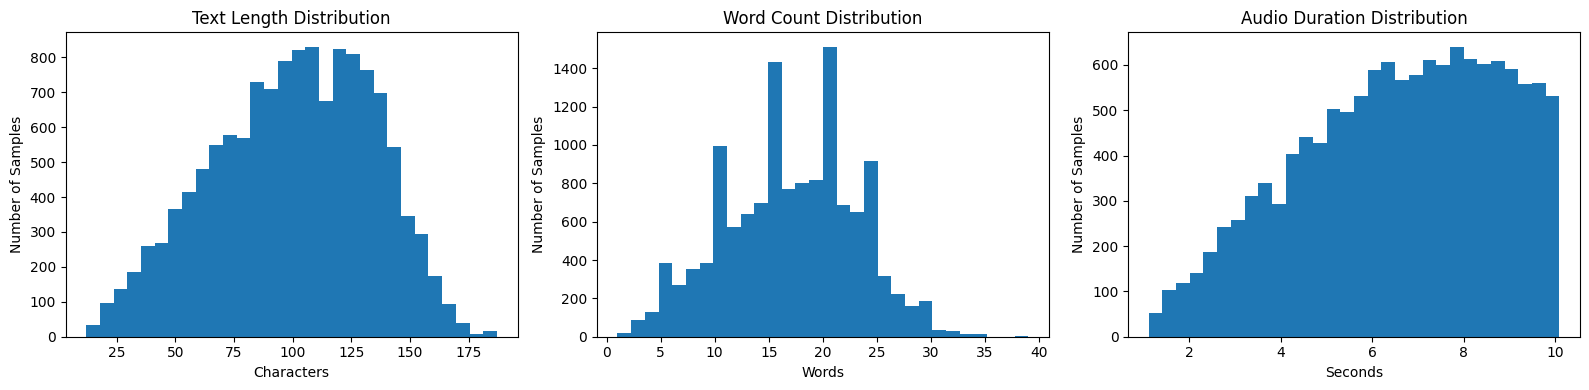

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(df["text_length"].dropna(), bins=30)
axes[0].set_title("Text Length Distribution")
axes[0].set_xlabel("Characters")

axes[1].hist(df["word_count"].dropna(), bins=30)
axes[1].set_title("Word Count Distribution")
axes[1].set_xlabel("Words")

axes[2].hist(df["duration_seconds"].dropna(), bins=30)
axes[2].set_title("Audio Duration Distribution")
axes[2].set_xlabel("Seconds")

for ax in axes:
    ax.set_ylabel("Number of Samples")

plt.tight_layout()
plt.show()#number12

### 3. Reproducible Dataset Splitting

The dataset was divided into training, validation and test sets using an 80:10:10 ratio and a fixed random seed of 42. The same split is intended to be used across the experimental models to ensure a fair comparison. The test set is reserved for final evaluation, while the validation set can be used for model selection and hyperparameter tuning.

The split manifests preserve the sample identifiers and corresponding audio paths so that each experiment uses the same data allocation.

In [13]:
from sklearn.model_selection import train_test_split

SEED = 42

# Split 80% training and 20% temporary data.
train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    random_state=SEED,
    shuffle=True
)

# Split the remaining 20% equally into validation and test.
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    shuffle=True
)

print("Total:", len(df))
print(f"Train: {len(train_df)} ({len(train_df)/len(df):.2%})")
print(f"Validation: {len(val_df)} ({len(val_df)/len(df):.2%})")
print(f"Test: {len(test_df)} ({len(test_df)/len(df):.2%})")

# Verify no overlap.
train_ids = set(train_df["id"])
val_ids = set(val_df["id"])
test_ids = set(test_df["id"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)
assert len(train_df) + len(val_df) + len(test_df) == len(df)

print("No overlap between the three splits.")#number14

Total: 13100
Train: 10480 (80.00%)
Validation: 1310 (10.00%)
Test: 1310 (10.00%)
No overlap between the three splits.


In [14]:
import json
from pathlib import Path

OUTPUT_DIR = Path("/content/TTS_Data_Preprocessing")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Select columns needed for handoff.
manifest_columns = [
    "id",
    "normalized_text",
    "audio_path",
    "duration_seconds"
]

train_df[manifest_columns].to_csv(
    OUTPUT_DIR / "train.csv", index=False
)
val_df[manifest_columns].to_csv(
    OUTPUT_DIR / "validation.csv", index=False
)
test_df[manifest_columns].to_csv(
    OUTPUT_DIR / "test.csv", index=False
)

# Export the dataset statistics.
df[
    ["id", "text_length", "word_count",
     "duration_seconds", "sample_rate", "channels"]
].to_csv(
    OUTPUT_DIR / "dataset_statistics.csv",
    index=False
)

# Export configuration for reproducibility.
config = {
    "dataset": "LJSpeech-1.1",
    "total_records": len(df),
    "split_ratio": {
        "train": 0.80,
        "validation": 0.10,
        "test": 0.10
    },
    "random_seed": SEED,
    "text_column": "normalized_text",
    "audio_sample_rate_expected": 22050,
    "audio_path_base": "/content/LJSpeech-1.1/wavs"
}

with open(
    OUTPUT_DIR / "preprocessing_config.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(config, f, indent=2, ensure_ascii=False)

print("Exported files:")
for path in sorted(OUTPUT_DIR.iterdir()):
    print(path.name, "-", path.stat().st_size, "bytes")#number15

Exported files:
dataset_statistics.csv - 621117 bytes
preprocessing_config.json - 285 bytes
test.csv - 227861 bytes
train.csv - 1813107 bytes
validation.csv - 228359 bytes


In [15]:

from pathlib import Path
import pandas as pd
import json

OUTPUT_DIR = Path("/content/TTS_Data_Preprocessing")

# 1. Load exported files
train = pd.read_csv(OUTPUT_DIR / "train.csv")
val = pd.read_csv(OUTPUT_DIR / "validation.csv")
test = pd.read_csv(OUTPUT_DIR / "test.csv")
stats = pd.read_csv(OUTPUT_DIR / "dataset_statistics.csv")

with open(
    OUTPUT_DIR / "preprocessing_config.json",
    "r",
    encoding="utf-8"
) as f:
    config = json.load(f)

# 2. Check split sizes
print("=== 1. Split sizes ===")
print(f"Train:      {len(train):,} (expected 10,480)")
print(f"Validation: {len(val):,} (expected 1,310)")
print(f"Test:       {len(test):,} (expected 1,310)")
print(f"Total:      {len(train) + len(val) + len(test):,}")

# 3. Check duplicate IDs and overlap
print("\n=== 2. Duplicate and overlap checks ===")

train_ids = set(train["id"])
val_ids = set(val["id"])
test_ids = set(test["id"])

print("Duplicate IDs within train:", train["id"].duplicated().sum())
print("Duplicate IDs within validation:", val["id"].duplicated().sum())
print("Duplicate IDs within test:", test["id"].duplicated().sum())

print("Train/validation overlap:", len(train_ids & val_ids))
print("Train/test overlap:", len(train_ids & test_ids))
print("Validation/test overlap:", len(val_ids & test_ids))

all_ids = train_ids | val_ids | test_ids
print("Unique IDs across all splits:", len(all_ids))
print("Statistics rows:", len(stats))
print("Statistics duplicate IDs:", stats["id"].duplicated().sum())

# 4. Check missing values
print("\n=== 3. Missing-value checks ===")
for name, data in [
    ("Train", train),
    ("Validation", val),
    ("Test", test)
]:
    print(f"\n{name}:")
    print(data[["id", "normalized_text", "audio_path",
                "duration_seconds"]].isna().sum())

# 5. Check whether audio files exist
print("\n=== 4. Audio file checks ===")
all_manifest = pd.concat([train, val, test], ignore_index=True)

missing_paths = all_manifest["audio_path"].isna().sum()
missing_files = [
    p for p in all_manifest["audio_path"].dropna()
    if not Path(p).is_file()
]

print("Missing audio_path values:", missing_paths)
print("Audio files not found:", len(missing_files))
if missing_files:
    print("Examples:", missing_files[:5])

# 6. Check configuration
print("\n=== 5. Configuration ===")
print(json.dumps(config, indent=2, ensure_ascii=False))

# 7. Summary
print("\n=== 6. Summary ===")
print("Total manifest rows:", len(all_manifest))
print("Total unique manifest IDs:", all_manifest["id"].nunique())
print("Total statistics rows:", len(stats))#number16


=== 1. Split sizes ===
Train:      10,480 (expected 10,480)
Validation: 1,310 (expected 1,310)
Test:       1,310 (expected 1,310)
Total:      13,100

=== 2. Duplicate and overlap checks ===
Duplicate IDs within train: 0
Duplicate IDs within validation: 0
Duplicate IDs within test: 0
Train/validation overlap: 0
Train/test overlap: 0
Validation/test overlap: 0
Unique IDs across all splits: 13100
Statistics rows: 13100
Statistics duplicate IDs: 0

=== 3. Missing-value checks ===

Train:
id                  0
normalized_text     0
audio_path          0
duration_seconds    0
dtype: int64

Validation:
id                  0
normalized_text     0
audio_path          0
duration_seconds    0
dtype: int64

Test:
id                  0
normalized_text     0
audio_path          0
duration_seconds    0
dtype: int64

=== 4. Audio file checks ===
Missing audio_path values: 0
Audio files not found: 0

=== 5. Configuration ===
{
  "dataset": "LJSpeech-1.1",
  "total_records": 13100,
  "split_ratio": {
  

In [16]:

import shutil
from pathlib import Path

OUTPUT_DIR = Path("/content/TTS_Data_Preprocessing")
ZIP_PATH = "/content/TTS_Data_Preprocessing.zip"

shutil.make_archive(
    ZIP_PATH.removesuffix(".zip"),
    "zip",
    root_dir=OUTPUT_DIR
)

print("Package created:", ZIP_PATH)
print("Package size:", Path(ZIP_PATH).stat().st_size, "bytes")


Package created: /content/TTS_Data_Preprocessing.zip
Package size: 878233 bytes


### Audio Properties Validation

This step validates the technical properties of the LJSpeech-1.1 audio files. It checks the sample rate, number of audio channels, duration, and audio readability. These checks help identify inconsistencies that could affect TTS model training and evaluation.

The validation results will be compared with the expected sample rate of 22,050 Hz. The original audio files will not be modified.

In [17]:
%pip install soundfile

In [18]:
from pathlib import Path
import soundfile as sf
import pandas as pd
import numpy as np

# Dataset paths
DATASET_DIR = Path("/content/LJSpeech-1.1")
AUDIO_DIR = DATASET_DIR / "wavs"
METADATA_PATH = DATASET_DIR / "metadata.csv"

EXPECTED_SAMPLE_RATE = 22050

# Get WAV files
audio_files = sorted(AUDIO_DIR.glob("*.wav"))

print(f"Audio directory: {AUDIO_DIR}")
print(f"Number of WAV files: {len(audio_files)}")

# Inspect every audio file
audio_results = []
read_errors = []

for audio_path in audio_files:
    try:
        info = sf.info(str(audio_path))

        audio_results.append({
            "id": audio_path.stem,
            "audio_path": str(audio_path),
            "sample_rate": info.samplerate,
            "channels": info.channels,
            "duration_seconds": info.duration,
            "frames": info.frames,
            "subtype": info.subtype
        })

    except Exception as e:
        read_errors.append({
            "id": audio_path.stem,
            "error": str(e)
        })

audio_df = pd.DataFrame(audio_results)

print("\n=== Audio Readability ===")
print(f"Readable WAV files: {len(audio_df)}")
print(f"Files with read errors: {len(read_errors)}")

if not audio_df.empty:
    print("\n=== Sample Rate Distribution ===")
    print(audio_df["sample_rate"].value_counts().sort_index())

    print("\n=== Channel Distribution ===")
    print(audio_df["channels"].value_counts().sort_index())

    print("\n=== Duration Statistics (seconds) ===")
    print(
        audio_df["duration_seconds"]
        .describe()
        .round(3)
        .to_string()
    )

    print("\n=== Expected Sample Rate Check ===")
    correct_sr = audio_df["sample_rate"] == EXPECTED_SAMPLE_RATE
    print(f"Expected sample rate: {EXPECTED_SAMPLE_RATE} Hz")
    print(f"Files with expected sample rate: {correct_sr.sum()}")
    print(f"Files with unexpected sample rate: {(~correct_sr).sum()}")

    print("\n=== Mono Audio Check ===")
    mono = audio_df["channels"] == 1
    print(f"Mono files: {mono.sum()}")
    print(f"Non-mono files: {(~mono).sum()}")

    print("\n=== Duration Range Check ===")
    print(f"Shortest duration: {audio_df['duration_seconds'].min():.3f} s")
    print(f"Longest duration: {audio_df['duration_seconds'].max():.3f} s")
    print(f"Zero-duration files: {(audio_df['duration_seconds'] <= 0).sum()}")

if read_errors:
    print("\n=== First 10 Read Errors ===")
    print(pd.DataFrame(read_errors).head(10).to_string(index=False))
else:
    print("\nAll discovered WAV files were readable.")

Audio directory: /content/LJSpeech-1.1/wavs
Number of WAV files: 13100

=== Audio Readability ===
Readable WAV files: 13100
Files with read errors: 0

=== Sample Rate Distribution ===
sample_rate
22050    13100
Name: count, dtype: int64

=== Channel Distribution ===
channels
1    13100
Name: count, dtype: int64

=== Duration Statistics (seconds) ===
count    13100.000
mean         6.574
std          2.185
min          1.110
25%          4.988
50%          6.764
75%          8.390
max         10.096

=== Expected Sample Rate Check ===
Expected sample rate: 22050 Hz
Files with expected sample rate: 13100
Files with unexpected sample rate: 0

=== Mono Audio Check ===
Mono files: 13100
Non-mono files: 0

=== Duration Range Check ===
Shortest duration: 1.110 s
Longest duration: 10.096 s
Zero-duration files: 0

All discovered WAV files were readable.


### Audio–Metadata Consistency and Quality Checks

This step compares the discovered WAV files with the dataset metadata and checks whether each audio file can be decoded. It also identifies unexpected sample rates, channel counts, and durations.

The results provide evidence of dataset integrity and help determine whether additional audio preprocessing, such as resampling or channel conversion, is necessary. No resampling or audio modification is performed in this step.

In [19]:
# Expected metadata IDs
metadata_df = df.copy()

metadata_ids = set(metadata_df["id"].str.strip())
audio_ids = {p.stem for p in audio_files}

# Compare IDs
audio_without_metadata = sorted(audio_ids - metadata_ids)
metadata_without_audio = sorted(metadata_ids - audio_ids)

# Audio properties
if not audio_df.empty:
    unexpected_sample_rate = audio_df[
        audio_df["sample_rate"] != EXPECTED_SAMPLE_RATE
    ]

    non_mono_audio = audio_df[audio_df["channels"] != 1]

    # Flag unusually short/long files for review.
    suspicious_duration = audio_df[
        (audio_df["duration_seconds"] < 0.1) |
        (audio_df["duration_seconds"] > 30)
    ]
else:
    unexpected_sample_rate = pd.DataFrame()
    non_mono_audio = pd.DataFrame()
    suspicious_duration = pd.DataFrame()

print("=== Metadata–Audio Consistency ===")
print(f"Metadata records: {len(metadata_df)}")
print(f"Unique metadata IDs: {metadata_df['id'].nunique()}")
print(f"Discovered WAV files: {len(audio_files)}")
print(f"Audio files without metadata: {len(audio_without_metadata)}")
print(f"Metadata records without audio: {len(metadata_without_audio)}")

print("\n=== Audio Property Issues ===")
print(f"Unreadable WAV files: {len(read_errors)}")
print(f"Unexpected sample rates: {len(unexpected_sample_rate)}")
print(f"Non-mono files: {len(non_mono_audio)}")
print(f"Suspicious durations (<0.1 s or >30 s): {len(suspicious_duration)}")

if audio_without_metadata:
    print("\nExamples: audio files without metadata")
    print(audio_without_metadata[:10])

if metadata_without_audio:
    print("\nExamples: metadata records without audio")
    print(metadata_without_audio[:10])

if len(unexpected_sample_rate):
    print("\nExamples: unexpected sample rates")
    print(
        unexpected_sample_rate[
            ["id", "sample_rate", "channels", "duration_seconds"]
        ].head(10).to_string(index=False)
    )

if len(non_mono_audio):
    print("\nExamples: non-mono files")
    print(
        non_mono_audio[
            ["id", "sample_rate", "channels"]
        ].head(10).to_string(index=False)
    )

if len(suspicious_duration):
    print("\nExamples: suspicious durations")
    print(
        suspicious_duration[
            ["id", "duration_seconds"]
        ].head(10).to_string(index=False)
    )

=== Metadata–Audio Consistency ===
Metadata records: 13100
Unique metadata IDs: 13100
Discovered WAV files: 13100
Audio files without metadata: 0
Metadata records without audio: 0

=== Audio Property Issues ===
Unreadable WAV files: 0
Unexpected sample rates: 0
Non-mono files: 0
Suspicious durations (<0.1 s or >30 s): 0


### Audio Validation Summary

This step produces a concise summary of the audio validation results. It reports the number of readable files, sample-rate consistency, channel consistency, and duration statistics.

The summary can be used as evidence in the dataset and preprocessing section of the project report. The results should be reported as observed measurements rather than assumed properties.

In [20]:
summary = {
    "total_wav_files_discovered": len(audio_files),
    "readable_wav_files": len(audio_df),
    "unreadable_wav_files": len(read_errors),
    "expected_sample_rate_hz": EXPECTED_SAMPLE_RATE,
    "files_at_expected_sample_rate": (
        int((audio_df["sample_rate"] == EXPECTED_SAMPLE_RATE).sum())
        if not audio_df.empty else 0
    ),
    "files_with_unexpected_sample_rate": len(unexpected_sample_rate),
    "mono_files": (
        int((audio_df["channels"] == 1).sum())
        if not audio_df.empty else 0
    ),
    "non_mono_files": len(non_mono_audio),
    "audio_without_metadata": len(audio_without_metadata),
    "metadata_without_audio": len(metadata_without_audio),
}

if not audio_df.empty:
    summary.update({
        "minimum_duration_seconds": round(
            float(audio_df["duration_seconds"].min()), 3
        ),
        "maximum_duration_seconds": round(
            float(audio_df["duration_seconds"].max()), 3
        ),
        "mean_duration_seconds": round(
            float(audio_df["duration_seconds"].mean()), 3
        ),
        "median_duration_seconds": round(
            float(audio_df["duration_seconds"].median()), 3
        ),
    })

summary_df = pd.DataFrame(
    list(summary.items()),
    columns=["check", "result"]
)

print(summary_df.to_string(index=False))

                            check    result
       total_wav_files_discovered 13100.000
               readable_wav_files 13100.000
             unreadable_wav_files     0.000
          expected_sample_rate_hz 22050.000
    files_at_expected_sample_rate 13100.000
files_with_unexpected_sample_rate     0.000
                       mono_files 13100.000
                   non_mono_files     0.000
           audio_without_metadata     0.000
           metadata_without_audio     0.000
         minimum_duration_seconds     1.110
         maximum_duration_seconds    10.096
            mean_duration_seconds     6.574
          median_duration_seconds     6.764
